[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shahin1717/ai-roadmap/blob/main/math/linear-algebra/linear-equations-and-gaussian-elimination/notebook.ipynb)

# Linear Equations and Gaussian Elimination: hands-on

This notebook goes with the [topic README](README.md). You will draw the two pictures of a linear system, write Gaussian elimination **from scratch** with a printed trace, redo the same steps with elementary matrices, and compare with `numpy.linalg.solve`. It needs only NumPy and Matplotlib and runs in a few seconds on a CPU.

Run the cells from top to bottom. After each demo, change a number and run it again.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 70
plt.rcParams["axes.titlesize"] = 11
np.set_printoptions(precision=3, suppress=True)

## 1. A system of equations is one equation, $A\mathbf{x} = \mathbf{b}$

Take the system $x + 2y = 5$ and $3x + 4y = 11$. Its coefficients form a matrix $A$, the right-hand sides form a vector $\mathbf{b}$, and the unknowns form a vector $\mathbf{x}$.

In [2]:
A = np.array([[1, 2],
              [3, 4]])
b = np.array([5, 11])

x = np.linalg.solve(A, b)
print("solution x =", x)
print("check A @ x =", A @ x)

solution x = [1. 2.]
check A @ x = [ 5. 11.]


**Two pictures of the same system.** The *row picture* draws each equation as a line and looks for the point where the lines meet. The *column picture* asks how many copies of each column of $A$ add up to $\mathbf{b}$.

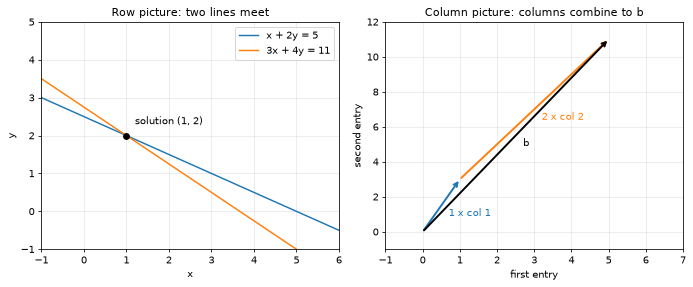

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2))

# Row picture: each equation is a line
xs = np.linspace(-1, 6, 50)
ax1.plot(xs, (5 - 1 * xs) / 2, label="x + 2y = 5")
ax1.plot(xs, (11 - 3 * xs) / 4, label="3x + 4y = 11")
ax1.scatter(*x, color="k", zorder=3)
ax1.annotate("solution (1, 2)", x + [0.2, 0.3])
ax1.set_xlim(-1, 6); ax1.set_ylim(-1, 5)
ax1.set_xlabel("x"); ax1.set_ylabel("y")
ax1.set_title("Row picture: two lines meet")
ax1.grid(alpha=0.3); ax1.legend()

# Column picture: x copies of column 1 plus y copies of column 2 give b
col1, col2 = A[:, 0], A[:, 1]
def arrow(ax, vec, start=(0, 0), color="C0", label=None):
    ax.annotate("", xy=np.add(start, vec), xytext=start,
                arrowprops=dict(arrowstyle="->", color=color, lw=2))
    if label:
        mid = np.add(start, np.array(vec) / 2)
        ax.text(mid[0] + 0.2, mid[1] - 0.6, label, color=color)
arrow(ax2, x[0] * col1, color="C0", label="1 x col 1")
arrow(ax2, x[1] * col2, start=x[0] * col1, color="C1", label="2 x col 2")
arrow(ax2, b, color="k", label="b")
ax2.set_xlim(-1, 7); ax2.set_ylim(-1, 12)
ax2.set_xlabel("first entry"); ax2.set_ylabel("second entry")
ax2.set_title("Column picture: columns combine to b")
ax2.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Both pictures show the same answer, $x = 1$ and $y = 2$. In the left picture it is where two lines cross. In the right picture it is the recipe "1 copy of the first column plus 2 copies of the second column gives $\mathbf{b}$".

### The three possible outcomes

A system can have one solution, none, or infinitely many. In the row picture these are lines that cross, lines that are parallel, and lines that are the same line.

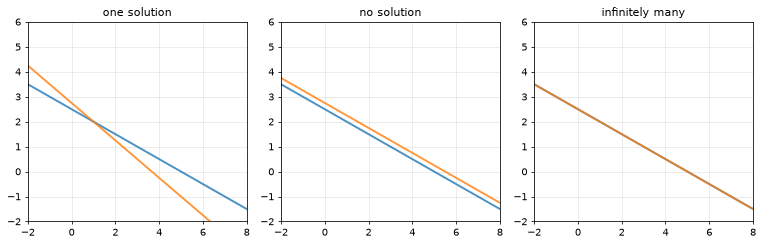

one solution     -> [1. 2.]
no solution      -> numpy refuses: Singular matrix
infinitely many  -> numpy refuses: Singular matrix


In [4]:
systems = {
    "one solution":       (np.array([[1, 2], [3, 4]]), np.array([5, 11])),
    "no solution":        (np.array([[1, 2], [2, 4]]), np.array([5, 11])),
    "infinitely many":    (np.array([[1, 2], [2, 4]]), np.array([5, 10])),
}

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
xs = np.linspace(-2, 8, 50)
for ax, (name, (M_, rhs)) in zip(axes, systems.items()):
    for row, r, color in zip(M_, rhs, ["C0", "C1"]):
        ax.plot(xs, (r - row[0] * xs) / row[1], color=color, lw=2, alpha=0.8)
    ax.set_xlim(-2, 8); ax.set_ylim(-2, 6)
    ax.set_title(name); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

for name, (M_, rhs) in systems.items():
    try:
        print(f"{name:16s} ->", np.linalg.solve(M_, rhs))
    except np.linalg.LinAlgError as error:
        print(f"{name:16s} -> numpy refuses:", error)

In the third panel the two lines lie on top of each other, so the orange line hides the blue one. NumPy reports "Singular matrix" for both of the last two systems, because it cannot tell you *which* of the two situations you are in, only that the matrix does not give a single answer. The rows of this $A$ are $(1,2)$ and $(2,4)$, one a multiple of the other, and the columns are also multiples of each other. The full story is in [vector spaces and subspaces](../vector-spaces-and-subspaces/README.md).

## 2. Gaussian elimination from scratch

Gaussian elimination subtracts multiples of one equation from the equations below it, so that each new equation has one fewer unknown. We write it as two small functions and let the first one **print every step**.

* `forward_eliminate` turns $A\mathbf{x} = \mathbf{b}$ into an upper triangular system $U\mathbf{x} = \mathbf{c}$. It swaps rows only if a pivot is zero.
* `back_substitute` solves the triangular system from the bottom up.

In [5]:
class ZeroPivotError(Exception):
    """Raised when a column has no usable pivot (the matrix is singular)."""
    def __init__(self, message, U, c):
        super().__init__(message)
        self.U, self.c = U, c


def show(U, c):
    """Print the augmented matrix [U | c] one row per line."""
    for row, ci in zip(U, c):
        print("   ", "  ".join(f"{v:6.2f}" for v in row), "|", f"{ci:6.2f}")


def forward_eliminate(A, b, pivoting="none", verbose=False):
    """Reduce A x = b to U x = c.

    pivoting="none": swap rows only when the pivot is exactly zero.
    pivoting="partial": always use the largest entry in the column (safer).
    """
    U = np.array(A, dtype=float)
    c = np.array(b, dtype=float)
    n = len(c)
    for k in range(n):
        if pivoting == "partial":
            p = k + np.argmax(np.abs(U[k:, k]))
        else:
            p = k if U[k, k] != 0 else next((i for i in range(k + 1, n) if U[i, k] != 0), None)
        tiny = 0.0 if pivoting == "none" else 1e-12     # what counts as "zero"
        if p is None or abs(U[p, k]) <= tiny:
            raise ZeroPivotError(f"no pivot in column {k}", U, c)
        if p != k:
            U[[k, p]], c[[k, p]] = U[[p, k]], c[[p, k]]
            if verbose:
                print(f"swap row {k + 1} and row {p + 1}")
        for i in range(k + 1, n):
            multiplier = U[i, k] / U[k, k]
            U[i, k:] -= multiplier * U[k, k:]
            c[i] -= multiplier * c[k]
            if verbose and multiplier != 0:
                print(f"row {i + 1} <- row {i + 1} - ({multiplier:g}) * row {k + 1}")
                show(U, c)
    return U, c


def back_substitute(U, c):
    """Solve U x = c for upper triangular U, starting from the last row."""
    n = len(c)
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        x[i] = (c[i] - U[i, i + 1:] @ x[i + 1:]) / U[i, i]
    return x

Here is the worked example from the README, with true solution $(1, 2, 1)$.

In [6]:
A = np.array([[ 2, 1, -1],
              [ 4, 3,  1],
              [-2, 2,  5]])
b = np.array([3, 11, 7])

print("start:")
show(A.astype(float), b.astype(float))
print()
U, c = forward_eliminate(A, b, verbose=True)
print("\npivots (diagonal of U):", np.diag(U))

start:
      2.00    1.00   -1.00 |   3.00
      4.00    3.00    1.00 |  11.00
     -2.00    2.00    5.00 |   7.00

row 2 <- row 2 - (2) * row 1
      2.00    1.00   -1.00 |   3.00
      0.00    1.00    3.00 |   5.00
     -2.00    2.00    5.00 |   7.00
row 3 <- row 3 - (-1) * row 1
      2.00    1.00   -1.00 |   3.00
      0.00    1.00    3.00 |   5.00
      0.00    3.00    4.00 |  10.00
row 3 <- row 3 - (3) * row 2
      2.00    1.00   -1.00 |   3.00
      0.00    1.00    3.00 |   5.00
      0.00    0.00   -5.00 |  -5.00

pivots (diagonal of U): [ 2.  1. -5.]


In [7]:
x = back_substitute(U, c)
print("x =", x)
print("A @ x =", A @ x, "(should equal b =", b, ")")

x = [1. 2. 1.]
A @ x = [ 3. 11.  7.] (should equal b = [ 3 11  7] )


## 3. Elimination with matrices

Each elimination step is a multiplication by an **elementary matrix**: the identity matrix with one extra number, $-\ell$, placed in the position of the entry we want to wipe out. Multiplying $A$ on the left by it performs that row operation.

In [8]:
def elementary(n, i, j, multiplier):
    """Identity matrix with -multiplier in row i, column j (counting from 1).
    Multiplying by it subtracts multiplier * (row j) from row i."""
    E = np.eye(n)
    E[i - 1, j - 1] = -multiplier
    return E


E21 = elementary(3, 2, 1, 2)    # row 2 <- row 2 - 2 * row 1
E31 = elementary(3, 3, 1, -1)   # row 3 <- row 3 + 1 * row 1
E32 = elementary(3, 3, 2, 3)    # row 3 <- row 3 - 3 * row 2

print("E21 =\n", E21)
print("E21 @ A =\n", E21 @ A)

E21 =
 [[ 1.  0.  0.]
 [-2.  1.  0.]
 [ 0.  0.  1.]]
E21 @ A =
 [[ 2.  1. -1.]
 [ 0.  1.  3.]
 [-2.  2.  5.]]


In [9]:
step1 = E21 @ A
step2 = E31 @ step1
U_from_E = E32 @ step2
print("after E21, E31, E32:\n", U_from_E)
print("same U as the loop? ", np.allclose(U_from_E, U))

# The three steps can be multiplied into ONE matrix, applied to A and b together
E = E32 @ E31 @ E21
print("\nE = E32 E31 E21 =\n", E)
print("E @ b =", E @ b, " (this is c)")

after E21, E31, E32:
 [[ 2.  1. -1.]
 [ 0.  1.  3.]
 [ 0.  0. -5.]]
same U as the loop?  True

E = E32 E31 E21 =
 [[ 1.  0.  0.]
 [-2.  1.  0.]
 [ 7. -3.  1.]]
E @ b = [ 3.  5. -5.]  (this is c)


Reading the output: `E @ A` gives the same triangular $U$ that the loop produced, and `E @ b` gives the same $\mathbf{c}$. Elimination is nothing more than multiplying by a product of simple matrices.

### The augmented matrix

Because the same row operations must be applied to $\mathbf{b}$, we often glue $\mathbf{b}$ onto $A$ as an extra column and write $[A \mid \mathbf{b}]$. One multiplication then updates both.

In [10]:
augmented = np.column_stack([A, b])
print("[A | b] =\n", augmented)
print("\nE @ [A | b] =\n", E @ augmented)

[A | b] =
 [[ 2  1 -1  3]
 [ 4  3  1 11]
 [-2  2  5  7]]

E @ [A | b] =
 [[ 2.  1. -1.  3.]
 [ 0.  1.  3.  5.]
 [ 0.  0. -5. -5.]]


## 4. Row exchanges

If a pivot position holds a zero, elimination cannot divide by it. Often a row further down has a nonzero entry in that column, and swapping the two rows fixes the problem. The swap is also a matrix, a **permutation matrix**: the identity with two rows exchanged.

In [11]:
A2 = np.array([[0, 2, 1],
               [1, 1, 1],
               [2, 1, 3]])
b2 = np.array([5, 4, 7])

U2, c2 = forward_eliminate(A2, b2, verbose=True)
x2 = back_substitute(U2, c2)
print("\nx =", x2, "| check A2 @ x =", A2 @ x2)

P12 = np.array([[0, 1, 0],
                [1, 0, 0],
                [0, 0, 1]])
print("\nP12 @ A2 =\n", P12 @ A2)

swap row 1 and row 2
row 3 <- row 3 - (2) * row 1
      1.00    1.00    1.00 |   4.00
      0.00    2.00    1.00 |   5.00
      0.00   -1.00    1.00 |  -1.00
row 3 <- row 3 - (-0.5) * row 2
      1.00    1.00    1.00 |   4.00
      0.00    2.00    1.00 |   5.00
      0.00    0.00    1.50 |   1.50

x = [1. 2. 1.] | check A2 @ x = [5. 4. 7.]

P12 @ A2 =
 [[1 1 1]
 [0 2 1]
 [2 1 3]]


The first line of the trace says the rows were swapped, and `P12 @ A2` shows the same swap done by a matrix.

## 5. When elimination fails: no pivot

Now a **singular** system, where one row is the sum of the other two. We try it with two different right-hand sides.

In [12]:
A3 = np.array([[1, 1, 1],
               [1, 2, 3],
               [2, 3, 4]])

for b3 in ([3, 6, 9], [3, 6, 10]):
    print("b =", b3)
    try:
        forward_eliminate(A3, b3)
    except ZeroPivotError as error:
        print("  elimination stops:", error)
        show(error.U, error.c)
    print()

b = [3, 6, 9]
  elimination stops: no pivot in column 2
      1.00    1.00    1.00 |   3.00
      0.00    1.00    2.00 |   3.00
      0.00    0.00    0.00 |   0.00

b = [3, 6, 10]
  elimination stops: no pivot in column 2
      1.00    1.00    1.00 |   3.00
      0.00    1.00    2.00 |   3.00
      0.00    0.00    0.00 |   1.00



Both runs stop at the same place: the last row has no pivot. The last row of the stuck system tells the two stories apart. With $\mathbf{b} = (3, 6, 9)$ it reads $0 = 0$, so the equations agree with each other and there are infinitely many solutions. With $\mathbf{b} = (3, 6, 10)$ it reads $0 = 1$, which is impossible, so there is no solution. A missing pivot is the signal that something special is happening; [vector spaces and subspaces](../vector-spaces-and-subspaces/README.md) explains what.

## 6. Why real solvers pick the biggest pivot

A pivot can be nonzero and still be a bad choice. If it is tiny, the multiplier $\ell$ becomes enormous, and rounding errors swamp the answer. The remedy, called **partial pivoting**, is to swap in the row with the largest entry in the column before every step.

In [13]:
A4 = np.array([[1e-20, 1.0],
               [1.0,   1.0]])
b4 = np.array([1.0, 2.0])      # true solution is very close to x = 1, y = 1

U4, c4 = forward_eliminate(A4, b4, pivoting="none")
print("no pivoting     :", back_substitute(U4, c4))

U4, c4 = forward_eliminate(A4, b4, pivoting="partial")
print("partial pivoting:", back_substitute(U4, c4))
print("numpy.linalg.solve:", np.linalg.solve(A4, b4))

no pivoting     : [0. 1.]
partial pivoting: [1. 1.]
numpy.linalg.solve: [1. 1.]


Without pivoting the answer for $x$ is completely wrong ($0$ instead of about $1$). With partial pivoting, and in NumPy, which does this for you, the answer is right. This is why you should call `np.linalg.solve` instead of writing elimination yourself in real work.

## 7. Compare with NumPy on a random system

A random $5 \times 5$ system with a seed, so the numbers are the same every time.

In [14]:
rng = np.random.default_rng(0)
A5 = rng.normal(size=(5, 5))
b5 = rng.normal(size=5)

U5, c5 = forward_eliminate(A5, b5, pivoting="partial")
mine = back_substitute(U5, c5)
theirs = np.linalg.solve(A5, b5)

print("my solution   :", mine)
print("numpy solution:", theirs)
print("largest difference:", np.max(np.abs(mine - theirs)))

my solution   : [ 1.639 -0.162 -0.229  0.988  0.169]
numpy solution: [ 1.639 -0.162 -0.229  0.988  0.169]
largest difference: 4.440892098500626e-16


## 8. How the cost grows

Elimination on an $n \times n$ system needs about $n^3/3$ multiplications. We count the multiplications and divisions that `forward_eliminate` performs for different sizes $n$ and compare them with $n^3/3$.

In [15]:
def count_multiplications(n):
    """Multiplications and divisions in forward elimination on an n x n system."""
    total = 0
    for k in range(n):
        for i in range(k + 1, n):
            total += 1              # the multiplier (one division)
            total += (n - k - 1)    # updating the rest of the row
            total += 1              # updating the right-hand side
    return total


ns = np.array([5, 10, 20, 40, 80, 160, 320])
counts = np.array([count_multiplications(n) for n in ns])
for n, k in zip(ns, counts):
    print(f"n = {n:4d}: {k:>9,} operations, n^3/3 = {n**3 / 3:>11,.0f}")

n =    5:        50 operations, n^3/3 =          42
n =   10:       375 operations, n^3/3 =         333
n =   20:     2,850 operations, n^3/3 =       2,667
n =   40:    22,100 operations, n^3/3 =      21,333
n =   80:   173,800 operations, n^3/3 =     170,667
n =  160: 1,378,000 operations, n^3/3 =   1,365,333
n =  320: 10,973,600 operations, n^3/3 =  10,922,667


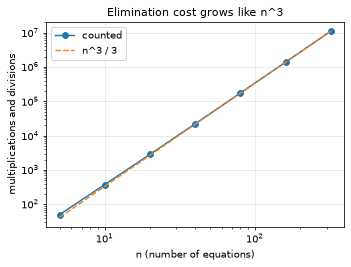

In [16]:
fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.loglog(ns, counts, "o-", label="counted")
ax.loglog(ns, ns ** 3 / 3, "--", label="n^3 / 3")
ax.set_xlabel("n (number of equations)")
ax.set_ylabel("multiplications and divisions")
ax.set_title("Elimination cost grows like n^3")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

The counted line sits on top of the $n^3/3$ line. Doubling $n$ multiplies the work by about 8.

## Recap and next steps

* A system of linear equations is one equation, $A\mathbf{x} = \mathbf{b}$. The row picture is lines or planes meeting; the column picture is a combination of columns equal to $\mathbf{b}$.
* There are three outcomes: one solution, none, or infinitely many.
* Elimination subtracts multiples of a pivot row to reach a triangular system, then back substitution finishes. Each step is multiplication by an elementary matrix, and a row swap is a permutation matrix.
* A missing pivot signals a singular matrix. Tiny pivots cause rounding trouble, which partial pivoting avoids.
* The work grows like $n^3/3$.

**Try it yourself:** change `b` in section 1 so that the second equation gives a different right-hand side, and predict the outcome before you run. Then do the [exercises](exercises/problems.md) and the [assignment](assignment.md).

Next topic: [Matrix Operations and LU Decomposition](../matrix-operations-and-lu-decomposition/README.md).